# Exploratory Data Analysis
I have 17.5K cars in my sample dataset from 2015-2020. I want to get a look at the data. One question I want to answer is whether I include every possible trim in my final dataset, or if I only include base models

In [116]:
import os
from pathlib import Path
import codecarbon.emissions_tracker as et

et.count_physical_cpus = lambda: 1

from codecarbon import EmissionsTracker

LOG_DIR = Path("data/carbon_logs")
LOG_DIR.mkdir(parents=True, exist_ok=True)

tracker = EmissionsTracker(
    project_name="eda_notebook",
    output_dir=str(LOG_DIR),
    output_file="eda_notebook.csv",
)
tracker.start()

[codecarbon WARNING @ 14:53:40] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon INFO @ 14:53:40] Emissions data (if any) will be saved to file c:\Users\kykin\OneDrive\Desktop\DSAN5550\dsan_5550_project\data\carbon_logs\eda_notebook.csv
[codecarbon INFO @ 14:53:40] Monitoring GPUs with indices: [0] out of 1 total GPUs
[codecarbon INFO @ 14:53:40] >>> Tracker's metadata:
[codecarbon INFO @ 14:53:40]   Platform system: Windows-11-10.0.26200-SP0
[codecarbon INFO @ 14:53:40]   Python version: 3.13.18
[codecarbon INFO @ 14:53:40]   CodeCarbon version: 3.3.2
[codecarbon INFO @ 14:53:40]   Available RAM : 31.773 GB
[codecarbon INFO @ 14:53:40]   CPU count: 32 thread(s) in 1 physical CPU(s)
[codecarbon INFO @ 14:53:40]   CPU model: 13th Gen Intel(R) Core(TM) i9-13950HX
[codecarbon INFO @ 14:53:40]   GPU count: 1
[codecarbon INFO @ 14:53:40]   GPU model: 1 x NVIDIA GeForce RTX 4070 Laptop GPU
[codecarbon INFO @ 14:53:40] Energy consumed for RAM : 0.000000 kWh. R

In [117]:
import pandas as pd
df = pd.read_csv('data/data_2015_2020/full_dataset.csv')
df.columns

Index(['make_id', 'model_id', 'submodel_id', 'trim_id', 'year', 'make',
       'model', 'submodel', 'trim', 'description', 'msrp', 'invoice',
       'body_type', 'engine_type', 'fuel_type', 'fuel_tank_capacity',
       'combined_mpg', 'epa_city_mpg', 'epa_highway_mpg', 'range_city',
       'range_highway', 'battery_capacity_electric',
       'epa_time_to_charge_hr_240v_electric', 'epa_kwh_100_mi_electric',
       'range_electric', 'epa_highway_mpg_electric', 'epa_city_mpg_electric',
       'epa_combined_mpg_electric'],
      dtype='str')

In [118]:
print(df['make'].unique())

<StringArray>
[        'Acura',    'Alfa Romeo',  'Aston Martin',          'Audi',
       'Bentley',           'BMW',       'Bugatti',         'Buick',
      'Cadillac',     'Chevrolet',      'Chrysler',         'Dodge',
       'Ferrari',          'FIAT',          'Ford',       'Genesis',
           'GMC',         'Honda',       'Hyundai',      'INFINITI',
        'Jaguar',          'Jeep',           'Kia',   'Lamborghini',
    'Land Rover',         'Lexus',       'Lincoln',         'Lotus',
      'Maserati',         'Mazda',       'McLaren', 'Mercedes-Benz',
          'MINI',    'Mitsubishi',        'Nissan',      'Polestar',
       'Porsche',           'Ram',   'Rolls-Royce',        'Subaru',
         'Tesla',        'Toyota',    'Volkswagen',         'Volvo',
         'smart',         'Scion']
Length: 46, dtype: str


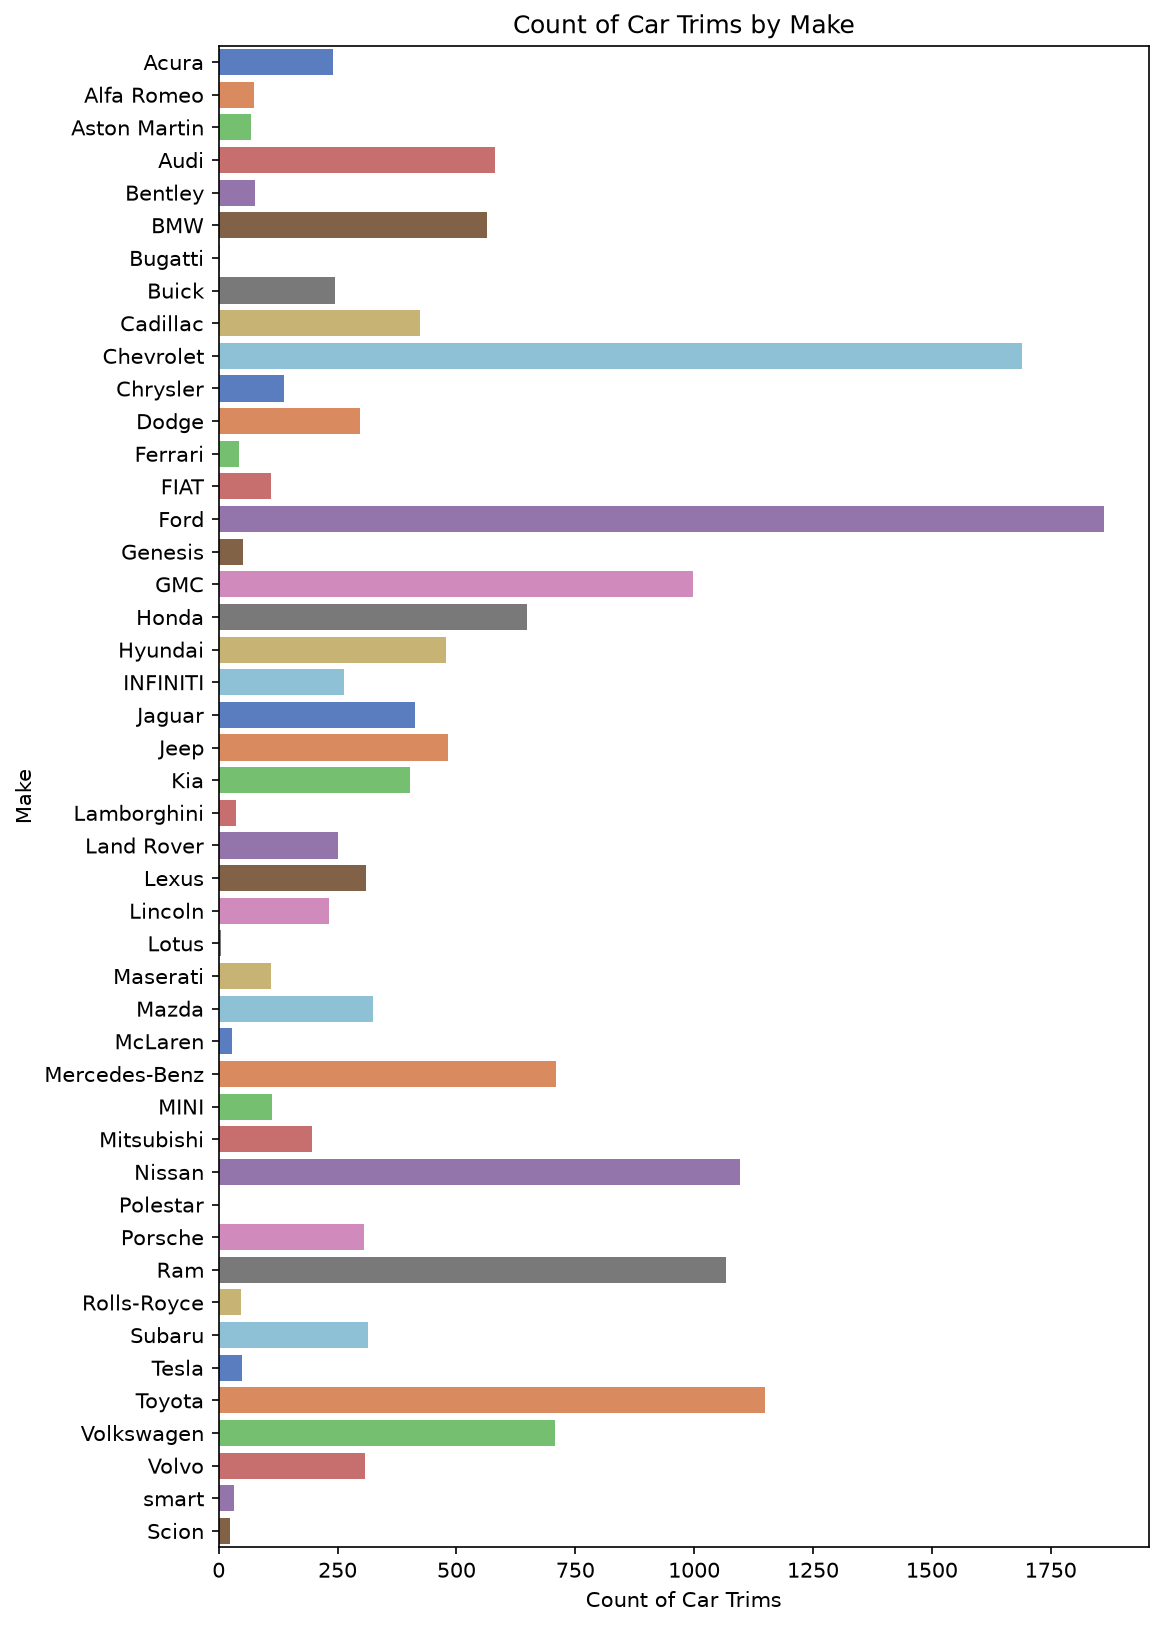

In [119]:
import matplotlib.pyplot as plt
import seaborn as sns

# bar chart of makes
fig, ax = plt.subplots(figsize=(8, 13))   # width, height in inches
sns.countplot(data=df, y="make", hue="make",
              palette="muted", legend=False, ax=ax)

plt.title("Count of Car Trims by Make")
plt.xlabel("Count of Car Trims")
plt.ylabel("Make")

plt.show()

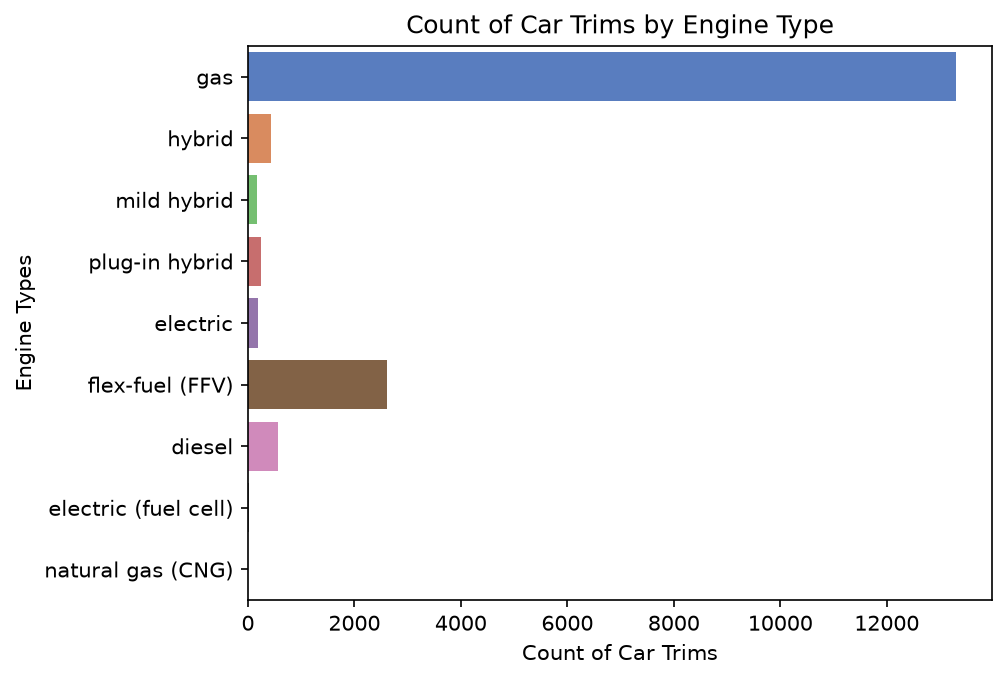

In [120]:
# count engine types
sns.countplot(data=df, y="engine_type", hue="engine_type",
              palette="muted", legend=False)

plt.title("Count of Car Trims by Engine Type")
plt.xlabel("Count of Car Trims")
plt.ylabel("Engine Types")

plt.show()

These categories need to be normalized, because this project isn't this granular about fuel type.

- flex-fuel engines, diesel cars, and natural gas are all internal combustion engines
- hybrid cars use a larger electric motor and self-charging battery and ICE, mild hybrids use a small electric motor and ICE,plug in hybrids have the largest battery and electric motor with ICE. mild hybrids can not run on electricity alone, hybrids can for short distances or low speeds, and plug in hybrids can run most of the day on electric. 
- fuel cell electric is very rare, so will combine with fuel cell

In [121]:
df["engine_type"] = df["engine_type"].replace({"electric (fuel cell)": "electric", "flex-fuel (FFV)": "gas", "natural gas (CNG)": "gas"})

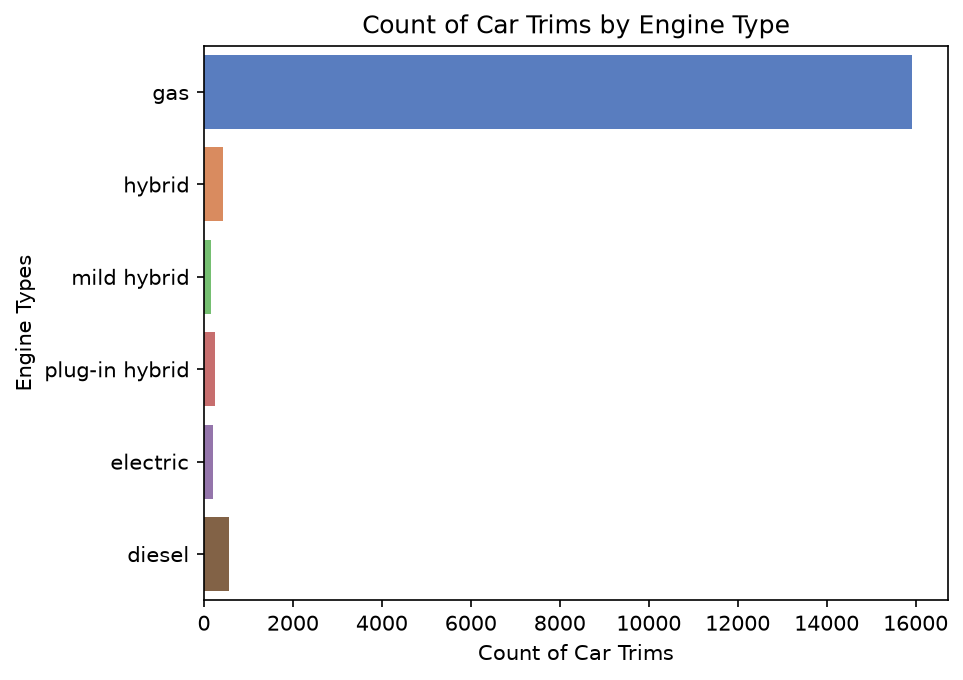

In [122]:
# count engine types
sns.countplot(data=df, y="engine_type", hue="engine_type",
              palette="muted", legend=False)

plt.title("Count of Car Trims by Engine Type")
plt.xlabel("Count of Car Trims")
plt.ylabel("Engine Types")

plt.show()

In [123]:
#how many duplicate rows are there
cols = [c for c in df.columns if c not in {"trim_id","trim","description", "msrp", "invoice"}]
dupes = df.duplicated(subset=cols, keep=False)
print(dupes.sum())

6517


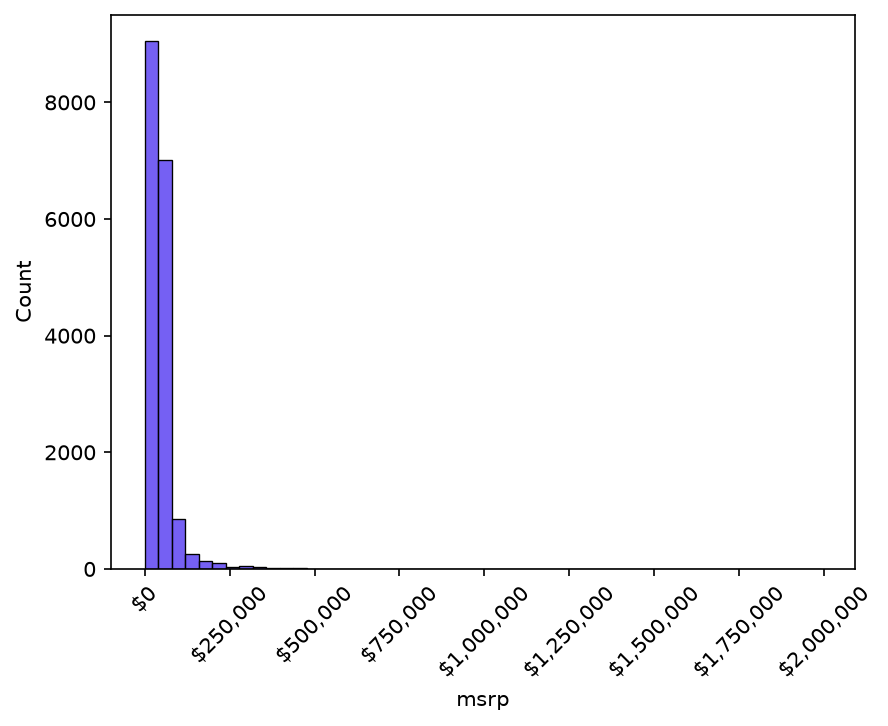

In [124]:
from matplotlib.ticker import FuncFormatter

ax = sns.histplot(data=df, x="msrp", bins=50, color="#472BF0")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.tick_params(axis="x", rotation=45)
plt.show()

In [125]:
cols = [c for c in df.columns if c not in {"trim_id","trim", "description", "msrp", "invoice"}]

# how many distinct values each candidate column has
print(df[cols].nunique().sort_values(ascending=False))
#there are 6.5k duplicates in everything except the trim package. This is good to know

submodel_id                            8027
submodel                                733
model_id                                713
model                                   710
range_highway                           365
range_city                              324
fuel_tank_capacity                      139
epa_city_mpg_electric                    76
epa_combined_mpg_electric                75
range_electric                           74
epa_highway_mpg_electric                 64
epa_city_mpg                             50
combined_mpg                             48
make_id                                  46
make                                     46
epa_highway_mpg                          45
epa_kwh_100_mi_electric                  44
epa_time_to_charge_hr_240v_electric      33
battery_capacity_electric                30
body_type                                22
fuel_type                                12
year                                      6
engine_type                     

# Data Cleaning
Some of the data is incomplete. For example, some gas cars have 0mpg listed, which is not correct.

In [126]:
zero_counts = (df == 0).sum()
print(zero_counts)

make_id                                   0
model_id                                  0
submodel_id                               0
trim_id                                   0
year                                      0
make                                      0
model                                     0
submodel                                  0
trim                                      0
description                               0
msrp                                     33
invoice                                 757
body_type                                 0
engine_type                               0
fuel_type                                 0
fuel_tank_capacity                        0
combined_mpg                              0
epa_city_mpg                              0
epa_highway_mpg                           0
range_city                             3153
range_highway                          3153
battery_capacity_electric                 0
epa_time_to_charge_hr_240v_elect

In [127]:
# remove rows where MSRP is 0, and drop invoice because it isn't actually relevant
#also range has a lot of 0s, but isn't actually relevant to what we're doing
df = df[df['msrp'] != 0]
df = df.drop(columns=['invoice', 'range_city','range_highway'])
df = df[df['fuel_type'] != 'hydrogen']


In [128]:
df.to_csv( 'data/data_2015_2020/edited_dataset.csv', index=False)

# Data Engineering
In this section, I will make extra columns for the calculations we need. Some examples are:
- the cost of the car + cost of home charging installation
- how much on gas it saves per year
- the time it takes for the car to offset its emissions

In Virginia, installing a level 2 charger at home costs $850–$2,700 according to https://everbreaker.com/ev-charger-installation-cost-virginia/

I will use the high range for my estimate, since car buyers should do their own research, but also know the high end of what to expect


In [129]:
import pandas as pd
import numpy as np
df = pd.read_csv('data/data_2015_2020/edited_dataset.csv')

In [130]:
# add charger installation cost
is_ev = df["engine_type"].isin(["electric", "plug-in hybrid"])
df["add_charger_install_va"] = np.where(is_ev, df["msrp"] + 2700, pd.NA)

In [131]:
ev = df[df["engine_type"] == "electric"]

The typical greenhouse gas emissions from one tank of the car's fuel

From https://www.epa.gov/greenvehicles/greenhouse-gas-emissions-typical-passenger-vehicle : 

- CO2 emissions from a gallon of gasoline: 8,887 grams CO2/ gallon
- CO2 emissions from a gallon of diesel: 10,180 grams CO2/ gallon

will record in metric tons (t) of co2



In [132]:
df['co2_per_tank_t'] = np.where(df["engine_type"]!='diesel', df["fuel_tank_capacity"]*0.008887,pd.NA)
df['co2_per_tank_t'] = np.where(df["engine_type"]=='diesel', df["fuel_tank_capacity"]*0.010180,df['co2_per_tank_t'])
df['co2_per_tank_t'] = np.where(df["engine_type"]=='electric', 0,df['co2_per_tank_t'])

There are 314 missing values still, which are all cars that don't have a listed fuel tank capacity

The average American driver drives 13,476 miles per year, according to the Federal Highway Administration https://www.fhwa.dot.gov/ohim/onh00/bar8.htm

The following cell will calcualte the number of gallons of gas that average driver is expected to use per year
plug-in hybrids will use the electric MPG column, because that covers average daily driving, and other hybrids will use the normal fuel mpg column. We will used combined mpg to get the most average calculation

In [133]:
is_ev = df["engine_type"].isin(["electric", "plug-in hybrid"])
df['avg_gal_gas_per_year'] = np.where(~is_ev, 13476/df["combined_mpg"],pd.NA)
df['avg_gal_gas_per_year'] = np.where(df["engine_type"]=='plug-in hybrid', 13476/df["epa_combined_mpg_electric"],df['avg_gal_gas_per_year'])
df['avg_gal_gas_per_year'] = np.where(df["engine_type"]=='electric', 0,df['avg_gal_gas_per_year'])

For electric and plug-in hybrid cars, it will likely cost money to charge the vehicle. We will calculate the number of kwh used in a year, which can be used to calcualte price later
kwh per year = average miles of an american driver per year over 100, times the kwh the vehicle uses per 100 miles

for plug in hybrids, they have an electric range that is often not the full 100 miles. this calculation calculates range/100 miles times average miles driven/100 times kwh of 100 miles electric

In [134]:
df['avg_kwh_per_year'] = np.where(df["engine_type"]=='electric', (13476/100)*df["epa_kwh_100_mi_electric"],pd.NA)
df['avg_kwh_per_year'] = np.where(df["engine_type"]=='plug-in hybrid', (13476/100)*(df['range_electric']/100)*(df["epa_kwh_100_mi_electric"]),df['avg_kwh_per_year'])

In [135]:
df.to_csv( 'data/data_2015_2020/edited_dataset.csv', index=False)

In [136]:
emissions = tracker.stop()
print(f"{emissions:.6f} kg CO2eq")

[codecarbon INFO @ 14:54:35] Energy consumed for RAM : 0.000309 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 14:54:35] Energy consumed for all GPUs : 0.000171 kWh. Total GPU Power : 13.499298128916458 W
[codecarbon INFO @ 14:54:35] Delta energy consumed for CPU with windows_emi : 0.000097 kWh, power : 33.52955677356766 W
[codecarbon INFO @ 14:54:35] Energy consumed for All CPU : 0.000533 kWh
[codecarbon INFO @ 14:54:35] 0.001013 kWh of electricity and 0.000000 L of water were used since the beginning.


0.000248 kg CO2eq
